# Temps de chaque étape des mutations, selon la taille de la molécule

Anciennes mutations (espace d'action par défaut d'evomol, sans règles) et nouvelles mutations (règles R1-R5 et
mutations d'`evomol/newmut`), sur **les mêmes molécules**. Pour chaque type de mutation, trois étapes :

| étape | ce qui est chronométré |
|---|---|
| **lister** | construire les mutations candidates (pour les nouvelles : avant les règles) |
| **vérifier** | tester les règles R1-R5 sur chaque candidate (nouvelles seulement). La ligne « (règles de départ) » est le calcul, une fois par molécule, des cycles, ponts et violations de la molécule de départ |
| **appliquer** | appliquer chaque mutation permise et écrire le SMILES canonique du résultat (comme pour le voisinage d'une marche) |

`SubstituteShiftMG` vérifie les règles pendant qu'elle liste (elle choisit le déplacement des doubles liaisons qui les
respecte) : son temps de vérification est compté dans « lister ». Temps « à froid » : mémoires vidées avant chaque
molécule. Le code est dans `scripts/newmut/newmut_time.py`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "scripts" / "newmut"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import newmut_time as nt                     # scripts/newmut/newmut_time.py (se place à la racine du projet)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 250)

## Molécules

Molécules visitées par des chaînes de mutations au hasard depuis le benzène (atomes C, O, N ; moitié par les
anciennes mutations, moitié par les nouvelles quand c'est possible : les anciennes font rarement de grosses
molécules), `PER_CLASS` par classe de taille, jusqu'à `MAX_ATOMS` atomes. Les chaînes s'arrêtent à `MAX_STEPS`
mutations ou quand elles atteignent `MAX_ATOMS`.

In [ ]:
PER_CLASS = 20                      # molécules par classe de taille
MAX_ATOMS = 100                    # taille maximale des molécules (classes : nt.SIZE_BINS)
MAX_STEPS = 1000                   # mutations par chaîne au plus
SEED = 0
OUT_DIR = Path("notebooks/random_walk/results/newmut_time")   # relatif à la racine du projet
OUT_DIR.mkdir(parents=True, exist_ok=True)

molecules = nt.pick_molecules(per_class=PER_CLASS, seed=SEED, max_steps=MAX_STEPS, max_atoms=MAX_ATOMS)
display(molecules.groupby("taille", observed=True).agg(molécules=("smiles", "size"), atomes_min=("n_atoms", "min"),
                                                       atomes_max=("n_atoms", "max"),
                                                       anciennes=("origine", lambda o: (o == "anciennes").sum())))

chaînes de mutations:   0%|          | 0/24000 [00:00<?, ?mutation/s]

,molécules,atomes_min,atomes_max,anciennes
taille,,,,
1-10,20,5,10,10
11-20,20,11,20,10
21-30,20,21,30,10
31-50,20,31,49,10
51-70,20,52,70,10
71-100,20,76,99,0


## Mesure

Quelques minutes jusqu'à 100 atomes : le voisinage grandit à peu près comme le carré de la taille.

In [3]:
times = nt.measure(molecules, max_atoms=MAX_ATOMS)
times.to_csv(OUT_DIR / "temps_par_molecule.csv", index=False)
print(f"{len(molecules)} molécules, {times.mutation.nunique()} lignes de mutation, résultats dans {OUT_DIR}")

mesure:   0%|          | 0/240 [00:00<?, ?molécule/s]

120 molécules, 14 lignes de mutation, résultats dans notebooks/random_walk/results/newmut_time


## Résumé par taille

ms par molécule, tous types de mutation confondus, pour chaque étape ; puis le rapport du temps total nouvelles /
anciennes.

lister            vérifier           appliquer               total                         rapport
condition anciennes nouvelles anciennes nouvelles anciennes nouvelles anciennes nouvelles nouvelles / anciennes
taille                                                                                                         
1-10            1.0       1.8       0.0       8.9       9.3      10.3      10.3      21.0                   2.0
11-20           1.0       3.4       0.0      23.5      17.3      22.8      18.3      49.6                   2.7
21-30           1.9       6.7       0.0      60.4      51.3      58.6      53.3     125.7                   2.4
31-50           3.6      12.0       0.0     163.6     172.3     153.4     175.8     329.0                   1.9
51-70           6.6      24.1       0.0     408.1     473.9     330.4     480.6     762.6                   1.6
71-100         10.1      65.8       0.1     838.2    1228.0     858.1    1238.1    1762.1                   1.4

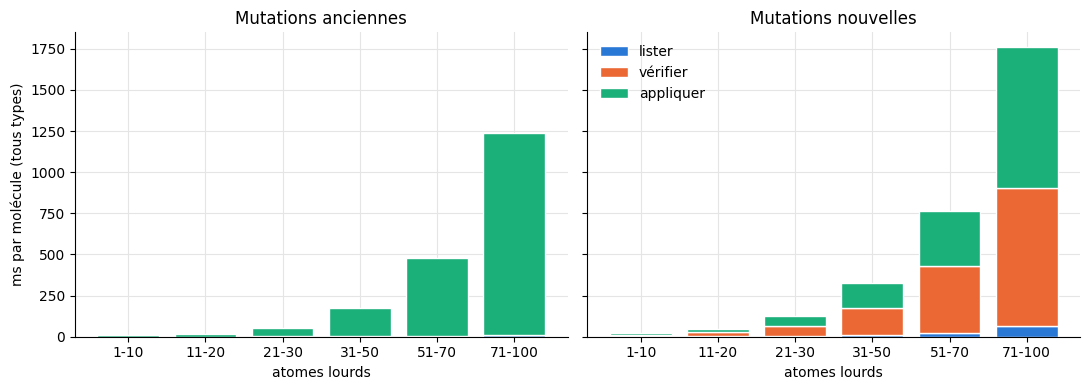

In [4]:
display(nt.summary(times))
nt.plot_steps(times, save=OUT_DIR / "etapes_par_taille.png")
plt.show()

## Anciennes mutations : chaque étape de chaque mutation

ms par molécule (moyenne sur les molécules de la classe de taille). Ligne TOTAL : somme des types.

In [5]:
display(nt.step_table(times, "anciennes"))

taille             1-10                            11-20                            21-30                            31-50                             51-70                            71-100                            
                 lister vérifier appliquer  total lister vérifier appliquer  total lister vérifier appliquer  total lister vérifier appliquer   total lister vérifier appliquer   total lister vérifier appliquer    total
AddAtomMG          0.18      0.0      3.32   3.49   0.05      0.0      2.80   2.84   0.07     0.00      6.90   6.97   0.09     0.00     15.67   15.77   0.16     0.00     36.80   36.96   0.18     0.00     63.56    63.75
ChangeBondMG       0.26      0.0      2.70   2.96   0.32      0.0      6.26   6.59   0.73     0.00     21.54  22.27   1.33     0.00     71.82   73.14   3.45     0.00    208.05  211.51   4.41     0.00    501.50   505.92
CutAtomMG          0.06      0.0      0.32   0.39   0.09      0.0      0.64   0.73   0.15     0.00      1.71   1.87   0.27     0.01      4.27    4.54   0.35     0.02      8.56    8.93   1.19     0.05     19.64    20.88
InsertCarbonMG     0.05      0.0      0.66   0.70   0.08      0.0      2.49   2.57   0.14     0.00      6.22   6.35   0.25     0.00     17.91   18.16   0.36     0.00     39.57   39.93   0.43     0.00     54.87    55.30
MoveGroupMG        0.16      0.0      1.12   1.28   0.24      0.0      3.01   3.25   0.45     0.00     10.40  10.85   0.88     0.00     51.88   52.77   1.42     0.00    153.99  155.42   2.65     0.00    543.86   546.51
RemoveAtomMG       0.23      0.0      0.13   0.36   0.17      0.0      0.24   0.41   0.30     0.00      0.42   0.72   0.57     0.01      1.24    1.82   0.67     0.01      2.66    3.35   0.92     0.03      6.18     7.14
SubstituteAtomMG   0.06      0.0      1.04   1.10   0.06      0.0      1.81   1.87   0.09     0.00      4.15   4.24   0.17     0.00      9.47    9.64   0.23     0.00     24.30   24.53   0.29     0.00     38.36    38.66
TOTAL              0.99      0.0      9.29  10.28   1.01      0.0     17.25  18.27   1.93     0.01     51.34  53.28   3.55     0.03    172.26  175.84   6.64     0.04    473.95  480.63  10.08     0.10   1227.98  1238.15

## Nouvelles mutations : chaque étape de chaque mutation

In [6]:
display(nt.step_table(times, "nouvelles"))

taille                  1-10                            11-20                            21-30                             31-50                             51-70                            71-100                            
                      lister vérifier appliquer  total lister vérifier appliquer  total lister vérifier appliquer   total lister vérifier appliquer   total lister vérifier appliquer   total lister vérifier appliquer    total
(règles de départ)      0.00     0.11      0.00   0.11   0.00     0.21      0.00   0.21   0.00     0.35      0.00    0.35   0.00     0.61      0.00    0.61   0.00     0.90      0.00    0.90   0.00     1.06      0.00     1.06
AnnelateMG              0.05     0.51      0.53   1.08   0.08     0.71      0.54   1.32   0.12     1.44      1.44    3.00   0.20     2.75      2.68    5.63   0.27     5.34      5.16   10.76   0.29     5.35      6.31    11.95
AppendAtomRuleMG        0.06     0.80      1.07   1.93   0.08     1.38      2.19   3.65   0.13     2.98      5.48    8.59   0.20     5.43     14.32   19.95   0.26     7.52     23.98   31.76   0.40    12.91     56.19    69.50
AromatizeMG             0.09     0.03      0.03   0.15   0.19     0.01      0.02   0.22   0.36     0.03      0.06    0.45   0.72     0.03      0.10    0.84   1.35     0.02      0.08    1.45   2.34     0.09      0.44     2.87
ChangeBondMG            0.19     1.81      1.13   3.13   0.37     7.49      3.68  11.53   0.73    25.16      9.31   35.20   1.33    83.04     24.10  108.47   2.21   236.46     51.97  290.64   4.11   499.14     83.20   586.44
CutAtomMG               0.06     0.55      0.29   0.90   0.10     1.26      0.63   1.99   0.16     2.80      1.70    4.66   0.25     4.54      2.90    7.70   0.34     8.74      5.71   14.79   0.54    25.32     18.12    43.97
FlipAlternatingPathMG   0.16     0.11      0.04   0.32   0.22     0.07      0.08   0.36   0.58     0.61      0.29    1.48   0.95     1.00      0.72    2.67   1.50     2.10      0.97    4.57   2.57     3.31      2.60     8.48
GraftFragmentMG         0.04     3.32      5.49   8.84   0.05     6.45     10.26  16.77   0.09    11.72     24.06   35.87   0.13    22.77     53.58   76.47   0.16    41.24    100.08  141.48   0.22    54.79    171.86   226.87
InsertCarbonMG          0.04     0.72      0.21   0.97   0.09     3.28      0.84   4.21   0.22     9.13      2.15   11.50   0.22    20.41      4.89   25.52   0.32    48.33     10.12   58.77   0.47    45.27     26.50    72.23
MoveGroupMG             0.14     0.81      0.66   1.61   0.25     2.27      2.39   4.91   0.40     5.74      8.68   14.82   0.73    22.12     37.24   60.08   1.24    55.53    107.26  164.03   2.61   185.56    420.35   608.53
RemoveAtomMG            0.10     0.16      0.09   0.36   0.19     0.35      0.26   0.79   0.28     0.46      0.44    1.18   0.43     0.93      1.15    2.50   0.61     1.87      2.23    4.71   0.87     5.36      5.46    11.70
SubstituteShiftMG       0.84     0.00      0.79   1.63   1.75     0.00      1.93   3.69   3.61     0.00      5.00    8.61   6.84     0.01     11.70   18.55  15.87     0.01     22.83   38.70  51.43     0.01     67.10   118.55
TOTAL                   1.77     8.92     10.34  21.04   3.36    23.47     22.81  49.65   6.67    60.41     58.62  125.70  12.00   163.63    153.37  328.99  24.11   408.05    330.40  762.56  65.84   838.17    858.14  1762.15

## Liste complète

Une ligne par (condition, mutation, taille) : nombre moyen de mutations candidates et permises, et ms de chaque étape.
Écrite dans `liste_etapes.csv`.

In [7]:
liste = nt.long_list(times)
liste.to_csv(OUT_DIR / "liste_etapes.csv", index=False)
display(liste)

,condition,mutation,taille,candidates,permises,lister,vérifier,appliquer,total
0,anciennes,AddAtomMG,1-10,16.95,16.95,0.18,0.00,3.32,3.49
1,anciennes,AddAtomMG,11-20,23.25,23.25,0.05,0.00,2.80,2.84
2,anciennes,AddAtomMG,21-30,38.10,38.10,0.07,0.00,6.90,6.97
3,anciennes,AddAtomMG,31-50,55.50,55.50,0.09,0.00,15.67,15.77
4,anciennes,AddAtomMG,51-70,77.85,77.85,0.16,0.00,36.80,36.96
...,...,...,...,...,...,...,...,...,...
109,nouvelles,SubstituteShiftMG,11-20,17.95,17.95,1.75,0.00,1.93,3.69
110,nouvelles,SubstituteShiftMG,21-30,29.30,29.30,3.61,0.00,5.00,8.61
111,nouvelles,SubstituteShiftMG,31-50,42.25,42.25,6.84,0.01,11.70,18.55
112,nouvelles,SubstituteShiftMG,51-70,59.30,59.30,15.87,0.01,22.83,38.70


## Une mutation en détail

Trait plein : nouvelles mutations ; tirets : anciennes (même nom quand la mutation existe des deux côtés).

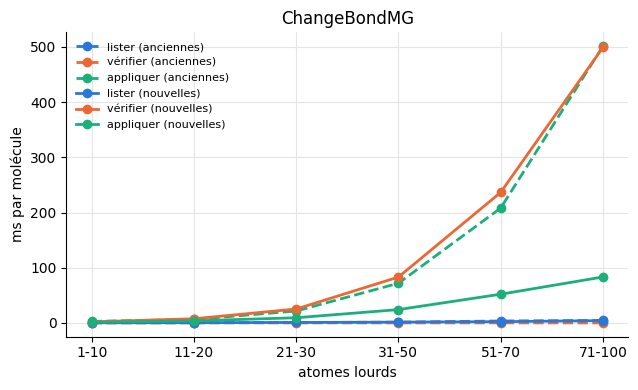

In [8]:
MUTATION = "ChangeBondMG"           # un nom de la colonne « mutation »

nt.plot_mutation(times, MUTATION)
plt.show()